# Lab : Content-Based Filtering Exercise

In this lab, we will generate item-item recommendations using content-based filtering.

Content-based filtering is a recommendation technique that suggests items to users based on the features and attributes of the items themselves and the preferences of the user. Here's a breakdown of how it works:

Feature Extraction: Each item in the system is described by a set of features or attributes. For example, in a movie recommendation system, features might include genre, director, cast, and plot summary.

User Profile Creation: A profile is built for each user based on their preferences and interactions with items. This profile might include features of the items the user has liked or interacted with in the past.

Recommendation Generation: The system compares the features of items to the user's profile to find items that match the user's preferences. For instance, if a user has a history of liking action movies, the system will recommend other action movies that have similar characteristics.

Personalization: Recommendations are tailored to the individual user based on their unique preferences and interactions, rather than relying on the preferences of other users.

### Step 1: Import Dependencies

We will be using the following Python packages:

- [numpy](https://numpy.org/): for scientific computing
- [pandas](https://pandas.pydata.org/): for data manipulation
- [scikit-learn](https://scikit-learn.org/stable/): for machine learning
- [matplotlib](https://matplotlib.org/), [seaborn](https://seaborn.pydata.org/): for data visualization

This code snippet is importing several essential libraries and modules used for data analysis, machine learning, and visualization in Python

In [4]:
import numpy as np
import pandas as pd
import sklearn
import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.simplefilter(action='ignore', category=FutureWarning)

### Step 2: Load the Data

Let's assume we're building a recommender system for a new movie platform


**Understanding Movie Features**

**Genres:** This indicates the type or category of the movie (e.g., Action, Comedy, Drama). Genres can be used to determine user preferences based on the types of movies they have liked in the past.

**Release Year**: This provides the year the movie was released. It can be used to filter or recommend movies from specific time periods, especially if a user prefers newer or older films.

In [5]:
# First, you'll need to mount your Google Drive to access files stored there.
from google.colab import drive
drive.mount('/content/drive')

# Define the file path
file_path = '/content/drive/MyDrive/Colab Notebooks/movies.csv'

# Load the CSV file into a DataFrame
movies = pd.read_csv(file_path)

#Display the First Few Rows of the DataFrame:
movies.head()


Mounted at /content/drive


,movieId,title,genres
0,1,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy
1,2,Jumanji (1995),Adventure|Children|Fantasy
2,3,Grumpier Old Men (1995),Comedy|Romance
3,4,Waiting to Exhale (1995),Comedy|Drama|Romance
4,5,Father of the Bride Part II (1995),Comedy


### Step 3: Data Preprocessing and Data Exploration

Before exploring our movie features dataset, we need to pre-process it:

1.  The genres are currently represented as a string with genres separated by a pipe (|). We will convert this string into a list to facilitate easier analysis.

2.  The title column includes the year appended at the end. We will extract the year from each title and create a new column to store this information separately.

#### Converting Genres from String Format to List

The genres column is currently a string separated with pipes. Let's convert this into a list using the "split" function.

We want
`"Adventure|Children|Fantasy"`
to convert to this:
`[Adventure, Children, Fantasy]`.

In [6]:
#lambda x: x.split("|") splits each genre string by the "|" delimiter, converting it from a single string into a list of genres.
movies['genres'] = movies['genres'].apply(lambda x: x.split("|"))
movies.head()

,movieId,title,genres
0,1,Toy Story (1995),"[Adventure, Animation, Children, Comedy, Fantasy]"
1,2,Jumanji (1995),"[Adventure, Children, Fantasy]"
2,3,Grumpier Old Men (1995),"[Comedy, Romance]"
3,4,Waiting to Exhale (1995),"[Comedy, Drama, Romance]"
4,5,Father of the Bride Part II (1995),[Comedy]


#### How many movie genres are there?
We can use Python's Counter to create a dictionary containing frequency counts of each genre in our dataset.
1.  Imports the Counter class from the collections module, which is useful for counting hashable objects.
2.   Counter(g for genres in movies['genres'] for g in genres): Creates a Counter object that counts how many times each genre appears across all movies.


In [7]:
# Imports the Counter class from the collections module, which is useful for counting hashable objects.
from collections import Counter

# Accesses the genres column, iterates over each genre in the list, counts how many times each genre appears across all movies.
genres_counts = Counter(g for genres in movies['genres']
                          for g in genres
                        )
# Print the number of unique genre labels
print(f"There are {len(genres_counts)} genre labels.\n")

# Display the genre counts
genres_counts

There are 20 genre labels.



Counter({'Adventure': 1263,
         'Animation': 611,
         'Children': 664,
         'Comedy': 3756,
         'Fantasy': 779,
         'Romance': 1596,
         'Drama': 4361,
         'Action': 1828,
         'Crime': 1199,
         'Thriller': 1894,
         'Horror': 978,
         'Mystery': 573,
         'Sci-Fi': 980,
         'War': 382,
         'Musical': 334,
         'Documentary': 440,
         'IMAX': 158,
         'Western': 167,
         'Film-Noir': 87,
         '(no genres listed)': 34})

There are 20 genre labels and 19 genres that are used to describe movies in this dataset. Some movies don't have any genres, hence the label `(no genres listed)`.

To clean the dataset by removing movies with (no genres listed) and update the genre counts to exclude this label:


1.   **Remove Movies with (no genres listed):**
Filter out the rows where the genre label is (no genres listed) from the DataFrame.
2.   **Update the Genre Counts:**
Remove the entry for (no genres listed) from the genres_counts dictionary and recompute the counts for the remaining genres.






In [ ]:
# Remove movies with '(no genres listed)'
movies = movies[movies['genres']!='(no genres listed)']

# Remove '(no genres listed)' from the genre counts dictionary
del genres_counts['(no genres listed)']

# Print the number of unique genre labels
print(f"There are {len(genres_counts)} genre labels.\n")

# Update genre counts after cleaning
genres_counts

There are 19 genre labels.



Counter({'Adventure': 1263,
         'Animation': 611,
         'Children': 664,
         'Comedy': 3756,
         'Fantasy': 779,
         'Romance': 1596,
         'Drama': 4361,
         'Action': 1828,
         'Crime': 1199,
         'Thriller': 1894,
         'Horror': 978,
         'Mystery': 573,
         'Sci-Fi': 980,
         'War': 382,
         'Musical': 334,
         'Documentary': 440,
         'IMAX': 158,
         'Western': 167,
         'Film-Noir': 87})

#### Which are the most prevalent genres?

*   We can use `Counter`'s most_common ( ) method to get the genres with the highest movie counts.
*   The top 5 genres are: Drama, Comedy, Thriller, Action and Romance.

This output shows the top 5 genres along with their counts, helping you understand which genres are most prevalent in your dataset.


*   The top 5 genres are: `Drama`, `Comedy`, `Thriller`, `Action` and `Romance`.
*   Let's also visualize genres popularity with a barplot.





In [ ]:
# returns a list of tuples, where each tuple contains a genre and its count.
print("The 5 most common genres: \n", genres_counts.most_common(5))

The 5 most common genres: 
 [('Drama', 4361), ('Comedy', 3756), ('Thriller', 1894), ('Action', 1828), ('Romance', 1596)]


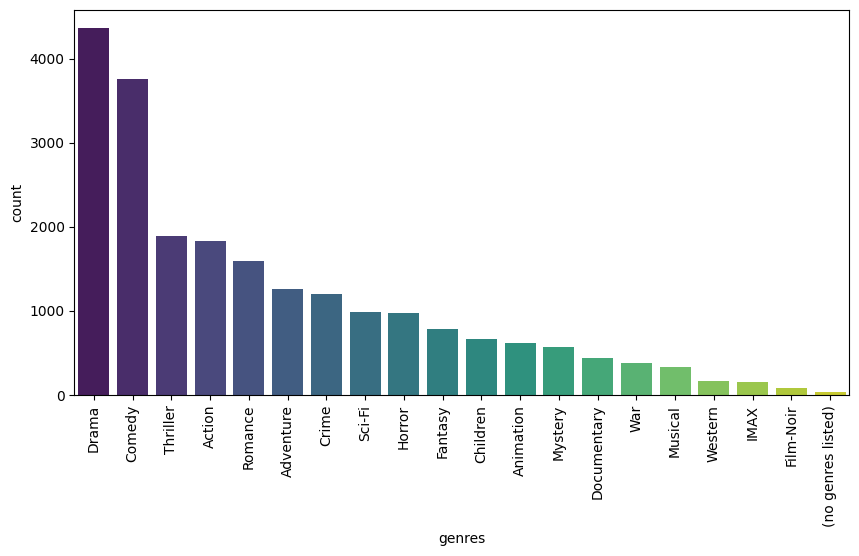

In [8]:
# Converts the Counter object into a list and resets the index of the DataFrame to default integer indices
# Renames the columns to 'genres' and 'count'
genres_counts_df = pd.DataFrame([genres_counts]).T.reset_index()
genres_counts_df.columns = ['genres', 'count']
genres_counts_df = genres_counts_df.sort_values(by='count', ascending=False)

# Plotting
plt.figure(figsize=(10,5))
sns.barplot(x='genres', y='count', data=genres_counts_df, palette='viridis')
plt.xticks(rotation=90)
plt.show()

Explanation of the plot

*   Data Preparation: Converts the Counter object to a DataFrame for easier
    manipulation and sorting.
*   Visualization: Uses Seaborn and Matplotlib to create a bar plot showing the frequency of each genre, helping to visualize the distribution of genres in the dataset.


The plot above shows that `Drama` and `Comedy` are ranked the two most **popular** movie genres. The **unpopular** movie genres are `Western`, `IMAX`, and `Film-Noir`.

#### Extract the 'year' from movie title

In our dataset, movie titles currently the year of release appended to it in brackets, e.g., `"Toy Story (1995)"`. We want to use the year of a movie's release as a feature. Extract the release year from the movie title string and create a new column (year) to store this information.



Function Description: `extract_year_from_title()`

The extract_year_from_title() function performs the following steps to parse
the year from the title string:

* generates a list by splitting each word by the space delimiters (e.g., `["Toy", "Story", "(1995)"]`)
* gets the last element of the list (e.g., `"(1995)"`)
* if the last element has brackets surrounding it, these `()` brackets get stripped (e.g., `"1995"`)
* converts the year into an integer **datatype**

In [10]:
# module for regular expression operations
import re

# Function: extract_year_from_title
# Description: Extract the release year from the movie title string and create a new column (year)
def extract_year_from_title(title):
    t = title.split(' ')
    year = None
    if re.search(r'\(\d+\)', t[-1]):
        year = t[-1].strip('()')
        year = int(year)
    return year

We test this function with a variable `"Toy Story (1995)"`:

In [11]:
title = "Toy Story (1995)"

# # Use the extract_year_from_title function to extract the year
year = extract_year_from_title(title)

# Print the extracted year and its type
print(f"Year of release: {year}")
print(type(year))

Year of release: 1995
<class 'int'>


- We can now apply this to all titles in our `movies` dataframe using Pandas' [apply()](https://pandas.pydata.org/pandas-docs/stable/reference/api/pandas.DataFrame.apply.html) method.
- You should now have a new column named year that contains the extracted release years.

In [12]:
# Apply the extract_year_from_title function to the 'title' column and create a new 'year' column
movies['year'] = movies['title'].apply(extract_year_from_title)
movies.head()

,movieId,title,genres,year
0,1,Toy Story (1995),"[Adventure, Animation, Children, Comedy, Fantasy]",1995.0
1,2,Jumanji (1995),"[Adventure, Children, Fantasy]",1995.0
2,3,Grumpier Old Men (1995),"[Comedy, Romance]",1995.0
3,4,Waiting to Exhale (1995),"[Comedy, Drama, Romance]",1995.0
4,5,Father of the Bride Part II (1995),[Comedy],1995.0


#### How many different years of release in movies dataset?
- movies['year']: Refers to the year column in the movies DataFrame.
- nunique(): This method counts the number of unique values in the year column.

There are over 106 years of release in our dataset.

In [13]:
# Get the number of unique years in the 'year' column
movies['year'].nunique()

106

#### What was the most popular decade of movie release?

We filtered out movies that do not have a year of release.

To round down a year to the nearest lower multiple of 10 to get the decade of a year.
- How It Works: By subtracting the remainder of the year divided by 10 from the year itself.
-Output: For any given year, it returns the largest multiple of 10 that is less than or equal to that year.

We can apply this functions to all years in our `movies` dataset. We'll use `round_down()` in this example to a create a new column called `'decade'`:

In [14]:
# The code filters out rows with non-null values in the year column. It effectively removes rows where the year is missin
movies = movies[~movies['year'].isnull()]
print(f"Number of movies after removing null years: {movies['movieId'].nunique()}")

Number of movies after removing null years: 9718


In [15]:
x = 1995
def round_down(year):
    return year - (year%10)

round_down(x)

1990

In [18]:
# For any given year, it returns the largest multiple of 10 that is less than or equal to that year.
movies['decade'] = movies['year'].apply(round_down)

### Step 4: Transforming the Data

In order to build a content-based filtering recommender, we need to set up our dataset so that rows represent movies and columns represent categorical features as binary values (i.e., genres).

We create the `genres` column. Each genre is represented as a separate binary feature. "1" indicates that the movie falls under a given genre, while "0" does not.
- Purpose: To create binary columns for each genre, showing whether a movie belongs to that genre.
- How It Works: Adds a column for each genre with 1 indicating it belongs to the genre, or 0 otherwise.
- Outcome: Facilitates genre-based analysis by providing a clear, numeric representation of genre category for each movie.

You can use the apply method with a lambda function or use str.contains if 'genres' is a string.
- Extracts the genre names from the genres_counts dictionary.
- If your 'genres' column is a string of genres separated by some delimiter (e.g., comma), you can use str.contains:

In [25]:
# Extract the genre names from the genres_counts dictionary.
genres = list(genres_counts.keys())

# Add genres column and apply with a lambda function
for g in genres:
    movies[g] = movies['genres'].transform(lambda x: int(g in x))

Let's take a look at what the movie genres columns look like:

In [26]:
movies[genres].head()

,Adventure,Animation,Children,Comedy,Fantasy,Romance,Drama,Action,Crime,Thriller,Horror,Mystery,Sci-Fi,War,Musical,Documentary,IMAX,Western,Film-Noir,(no genres listed)
0,1,1,1,1,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
1,1,0,1,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
2,0,0,0,1,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0
3,0,0,0,1,0,1,1,0,0,0,0,0,0,0,0,0,0,0,0,0
4,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0


We create the `decade` column by converting the categorical column into  one-hot encoding.
- Each unique value in the 'decade' column becomes a new column, and a 1 or 0 is used to indicate the presence or absence of each category in the original column.

- We use pandas' [get_dummies()](https://pandas.pydata.org/pandas-docs/stable/reference/api/pandas.get_dummies.html) function, for one-hot encoding

In [27]:
# Converts the categorical 'decade' column into a one-hot encoded DataFrame
movie_decades = pd.get_dummies(movies['decade'])

# Displays the first few rows of the resulting dataFrame
movie_decades.head()

,1900.0,1910.0,1920.0,1930.0,1940.0,1950.0,1960.0,1970.0,1980.0,1990.0,2000.0,2010.0
0,False,False,False,False,False,False,False,False,False,True,False,False
1,False,False,False,False,False,False,False,False,False,True,False,False
2,False,False,False,False,False,False,False,False,False,True,False,False
3,False,False,False,False,False,False,False,False,False,True,False,False
4,False,False,False,False,False,False,False,False,False,True,False,False


Now, let's create a new `movie_features` dataframe by combining our genres features and decade features.

**movies[genres]**:

- This selects the columns from the movies DataFrame that correspond to each genre.
-Each column here is a binary indicator of whether a movie belongs to a particular genre.

**movie_decades:**

- This dataFrame contains the one-hot encoded columns for the 'decade' feature,
   where each column represents a different decade, e.g. 1920s, 1930s, 1940s
   
**pd.concat([movies[genres], movie_decades], axis=1):**

Concatenates the genre columns and the decade columns along the columns axis (axis=1), effectively combining the two sets of features into a single DataFrame.
We can do this using pandas' [concat](https://pandas.pydata.org/pandas-docs/stable/reference/api/pandas.concat.html) function which concatenates (appends) genres and decades into a single dataframe.

In [29]:
# Concatenates the genre columns and the decade columns
movie_features = pd.concat([movies[genres], movie_decades], axis=1)
movie_features.head()

,Adventure,Animation,Children,Comedy,Fantasy,Romance,Drama,Action,Crime,Thriller,...,1920.0,1930.0,1940.0,1950.0,1960.0,1970.0,1980.0,1990.0,2000.0,2010.0
0,1,1,1,1,1,0,0,0,0,0,...,False,False,False,False,False,False,False,True,False,False
1,1,0,1,0,1,0,0,0,0,0,...,False,False,False,False,False,False,False,True,False,False
2,0,0,0,1,0,1,0,0,0,0,...,False,False,False,False,False,False,False,True,False,False
3,0,0,0,1,0,1,1,0,0,0,...,False,False,False,False,False,False,False,True,False,False
4,0,0,0,1,0,0,0,0,0,0,...,False,False,False,False,False,False,False,True,False,False


Our `movie_features` dataframe is ready.
The movie_features DataFrame will now contain all the one-hot encoded features representing both genres and decades. This combined feature matrix is well-suited for use in machine learning algorithms

The next step is to start building our recommender.

### Step 5: Building a "Similar Movies" Recommender Using Cosine Similarity

We're going to build our item-item recommender using a similarity metric called [cosine similarity](https://en.wikipedia.org/wiki/Cosine_similarity).

Cosine similarity looks at the cosine angle between two vectors (e.g., $A$ and $B$). The smaller the cosine angle, the higher the degree of similarity between $A$ and $B$. You can calculate the similarity between $A$ and $B$ with this equation:

$$\cos(\theta) = \frac{A\cdot B}{||A|| ||B||}$$


**Calculate the cosine similarity matrix for the movie features using sklearn's cosine_similarity function**
- We're going to use scikit-learn's cosine similarity [function](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.pairwise.cosine_similarity.html) to generate a cosine similarity matrix of shape $(n_{\text{movies}}, n_{\text{movies}})$.
- With this cosine similarity matrix, we'll be able to extract movies that are most similar to the movie of interest.
- This matrix will help you understand how similar each movie is to every other movie based on the feature set you created.

After passing the `movie_features` dataframe into the `cosine_similarity()` function
-  we get a cosine similarity matrix of shape $(n_{\text{movies}}, n_{\text{movies}})$.

- This matrix is populated with values between 0 and 1 which represent the degree of similarity between movies along the x and y axes.

In [32]:
# import the cosine_similarity function from sklearn.metrics.pairwise
from sklearn.metrics.pairwise import cosine_similarity

# calculates the cosine similarity between every pair of rows
cosine_sim = cosine_similarity(movie_features, movie_features)
print(f"Dimensions of our movie features cosine similarity matrix: {cosine_sim.shape}")

Dimensions of our movie features cosine similarity matrix: (9718, 9718)


### Let's create a movie finder function

Let's say we want to get recommendations for movies that are similar to Jumanji. To get results from our recommender, we need to know the exact title of a movie in our dataset. In our dataset, Ice Age is actually listed as `'Ice Age: A Mammoth Christmas (2012)'`. If we misspell or forget to include its year of release, our recommender won't be able to identify which movie we're interested in.  

To make our recommender more user-friendly, we can use a Python package called [fuzzywuzzy](https://pypi.org/project/fuzzywuzzy/) which will find the most similar title to a string that you pass in.
- You're using the fuzzywuzzy library to find the closest matching movie title from a list.
- The process module contains functions to perform fuzzy string matching, including extractOne, which finds the best match.
- This can be very useful when you want to find movies that are similar to a given title, especially when dealing with slight misspellings or variations in movie names.

Create a function called `movie_finder()` which take advantage of `fuzzywuzzy`'s string matching algorithm to get the most similar title to a user-inputted string.

- all_titles: Converts the 'title' column from the movies DataFrame to a list of movie titles.
- process.extractOne(title, all_titles): Finds the closest match to the input title in the all_titles list. It returns a tuple where the first element is the closest match, and the second element is the similarity score.
- return closest_match[0]: Returns the closest matching title.



In [33]:
!pip install fuzzywuzzy
from fuzzywuzzy import process

# Function: movie_finder (title)
# Description: find the closest matching movie title from a list

def movie_finder(title):
    all_titles = movies['title'].tolist()
    closest_match = process.extractOne(title,all_titles)
    return closest_match[0]

/usr/local/lib/python3.10/dist-packages/fuzzywuzzy/fuzz.py:11: UserWarning: Using slow pure-python SequenceMatcher. Install python-Levenshtein to remove this warning
  warnings.warn('Using slow pure-python SequenceMatcher. Install python-Levenshtein to remove this warning')


Let's test this out with an example.

In [47]:
title = movie_finder('Ice Age : A Mammoth Christmas')
title

'Ice Age: A Mammoth Christmas (2011)'

To get relevant recommendations for our movie, we need to find its index in the cosine simialrity matrix. To identify which row we should be looking at, we can create a movie index mapper which maps a movie title to the index that it represents in our matrix.

Let's create a movie index dictionary called `movie_idx` where the keys are movie titles and values are movie indices:

In [48]:
movie_idx = dict(zip(movies['title'], list(movies.index)))
idx = movie_idx[title]
idx

8605

Using this handy `movie_idx` dictionary, we know that Ice Age is represented by index 8605 in our matrix. Let's get the top 10 most similar movies to Ice Age: A Mammoth's Christmas.

In [49]:
n_recommendations=10
sim_scores = list(enumerate(cosine_sim[idx]))
sim_scores = sorted(sim_scores, key=lambda x: x[1], reverse=True)
sim_scores = sim_scores[1:(n_recommendations+1)]
similar_movies = [i[0] for i in sim_scores]

`similar_movies` is an array of indices that represents the query's top 10 recommendations. We can get the corresponding movie titles by either creating an inverse `movie_idx` mapper or using `iloc` on the title column of the `movies` dataframe.

In [51]:
print(f"Because you watched {title}:")
movies['title'].iloc[similar_movies]

Because you watched Ice Age: A Mammoth Christmas (2011):


,title
8617,The Hobbit: The Battle of the Five Armies (2014)
9218,Gods of Egypt (2016)
7278,Alice in Wonderland (2010)
7365,"Last Airbender, The (2010)"
7478,Chronicles of Narnia: The Voyage of the Dawn T...
7496,Gulliver's Travels (2010)
7506,Season of the Witch (2011)
7679,Conan the Barbarian (2011)
7865,Mirror Mirror (2012)
8053,"Hobbit: An Unexpected Journey, The (2012)"


Cool! These recommendations seem pretty relevant to Ice Age and the animation films from the 2010s.

We can test our recommender further with other movie titles. For your convenience, I've packaged the steps into a single function which takes in the movie title of interest and number of recommendations.

In [54]:
 movies

,movieId,title,genres,year,decade,Adventure,Animation,Children,Comedy,Fantasy,...,Horror,Mystery,Sci-Fi,War,Musical,Documentary,IMAX,Western,Film-Noir,(no genres listed)
0,1,Toy Story (1995),"[Adventure, Animation, Children, Comedy, Fantasy]",1995.0,1990.0,1,1,1,1,1,...,0,0,0,0,0,0,0,0,0,0
1,2,Jumanji (1995),"[Adventure, Children, Fantasy]",1995.0,1990.0,1,0,1,0,1,...,0,0,0,0,0,0,0,0,0,0
2,3,Grumpier Old Men (1995),"[Comedy, Romance]",1995.0,1990.0,0,0,0,1,0,...,0,0,0,0,0,0,0,0,0,0
3,4,Waiting to Exhale (1995),"[Comedy, Drama, Romance]",1995.0,1990.0,0,0,0,1,0,...,0,0,0,0,0,0,0,0,0,0
4,5,Father of the Bride Part II (1995),[Comedy],1995.0,1990.0,0,0,0,1,0,...,0,0,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9737,193581,Black Butler: Book of the Atlantic (2017),"[Action, Animation, Comedy, Fantasy]",2017.0,2010.0,0,1,0,1,1,...,0,0,0,0,0,0,0,0,0,0
9738,193583,No Game No Life: Zero (2017),"[Animation, Comedy, Fantasy]",2017.0,2010.0,0,1,0,1,1,...,0,0,0,0,0,0,0,0,0,0
9739,193585,Flint (2017),[Drama],2017.0,2010.0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
9740,193587,Bungo Stray Dogs: Dead Apple (2018),"[Action, Animation]",2018.0,2010.0,0,1,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [41]:
def get_content_based_recommendations(title_string, n_recommendations=10):
    title = movie_finder(title_string)
    idx = movie_idx[title]
    sim_scores = list(enumerate(cosine_sim[idx]))
    sim_scores = sorted(sim_scores, key=lambda x: x[1], reverse=True)
    sim_scores = sim_scores[1:(n_recommendations+1)]
    similar_movies = [i[0] for i in sim_scores]
    print(f"Recommendations for {title}:")
    print(movies['title'].iloc[similar_movies])

In [57]:
get_content_based_recommendations('Iron Man', 5)

Recommendations for Iron Man (2008):
6946                 Earthsea (Legend of Earthsea) (2004)
4800    Lord of the Rings: The Return of the King, The...
6014                                    MirrorMask (2005)
6021                             Beowulf & Grendel (2005)
6266                                          Zoom (2006)
Name: title, dtype: object
